# Summary
The purpose of the following code is to verify bee behavior via visualization.

# Visualization of bee flight paths

## 1. Executing simulation
Execut one simulation and save the data.

In [ ]:
%matplotlib notebook

import pickle
import pandas as pd
from mesa.batchrunner import batch_run
from model import OpenCoverModel  
from tqdm import tqdm
import matplotlib.pyplot as plt

# ------------------------------
# User-defined simulation inputs
# ------------------------------

behavior = "my_behavior"  # Choose from: pure_levy, truncated_levy, composite_levy, biased_composite, my_behavior. (MORE Behaviors can bee added in model.py)
seed_value = 0               # Set the random seed
steps = 10 * 60          # Number of simulation steps
n_agents = 60                # Number of bees
landing_prob = 1.0
# reward_size = 5


# ------------------------------
# Run the simulation
# ------------------------------
param_dict = {
    "n_agents": n_agents,
    "bee_behavior": behavior,
    "landing_prob": landing_prob,
    # "reward_size": reward_size,
    "seed": seed_value
}


print(f"Running simulation for behavior: {behavior} with seed {seed_value}")

results = batch_run(
    model_cls=OpenCoverModel,
    parameters=param_dict,
    iterations=1,
    max_steps=steps,
    number_processes=1,               
    data_collection_period=1,         # Collect data every step
    display_progress=True
)


# ------------------------------
# Save the result
# ------------------------------
df = pd.DataFrame(results)
output_filename = f"sim_results_{behavior}_seed_{seed_value}.pkl"
with open(output_filename, "wb") as f:
    pickle.dump(results, f)

print(f"Simulation complete. Results saved to {output_filename}")

# Takes approximately 3min 40s for 2 hours of simulation with 60 bees at each hive with my_behavior for 2 hours of simulation time.

Running simulation for behavior: my_behavior with seed 0


  0%|          | 0/1 [00:00<?, ?it/s]

Simulation complete. Results saved to sim_results_my_behavior_seed_0.pkl


## 2. Visualize flight path

In [ ]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

In [ ]:
%matplotlib inline
def load_dataframe(filename):
    """Loads the dataframe from a pickle file."""
    with open(filename, "rb") as f:
        results = pickle.load(f)
    df = pd.DataFrame(results)
    return df


def vis_bees_path(df, bee_ids, start_time_str="09:00", duration_minutes=10, x_buffer=5):
    """
    Plot flight paths of selected bees with direction arrows,
    including the first beehive and relevant plant locations.

    Parameters:
        df (pd.DataFrame): Simulation dataframe.
        bee_ids (list of int): List of bee AgentIDs to visualize.
        start_time_str (str): Start time in HH:MM format (24h clock starting from 09:00).
        duration_minutes (int): Duration in minutes to plot.
        x_buffer (float): Extra range added to max x for plant inclusion.
        
    NOTE: Choose bees from beehive 1 (beeids 2 to 62). Need to add extra data "from hive" in model.py
    """
    def time_str_to_step(time_str):
        hh, mm = map(int, time_str.split(":"))
        return (hh - 9) * 3600 + mm * 60

    start_step = time_str_to_step(start_time_str)
    end_step = start_step + duration_minutes * 60

    # Filter bees
    bee_df = df[(df["Agent Type"] == "bee") &
                (df["Step"] >= start_step) &
                (df["Step"] < end_step) &
                (df["AgentID"].isin(bee_ids))].copy()
    
    if bee_df.empty:
        print("No bee data found for the given IDs and time window.")
        return

    # Extract bee positions
    bee_df[['x', 'y']] = bee_df['Bee Positions'].apply(pd.Series)

    # Get x-range from bee paths
    min_x = bee_df['x'].min()
    max_x = bee_df['x'].max()

    # Prepare figure
    plt.figure(figsize=(10, 6))
    cmap = plt.colormaps.get_cmap("tab10").resampled(len(bee_ids))

    # Plot bee flight paths
    for idx, bee_id in enumerate(bee_ids):
        track = bee_df[bee_df['AgentID'] == bee_id].sort_values(by="Step")
        x = track['x'].values
        y = track['y'].values
        u = x[1:] - x[:-1]
        v = y[1:] - y[:-1]

        plt.plot(x, y, label=f"Bee {bee_id}", color=cmap(idx), linewidth=1.5, alpha=0.7)
        plt.quiver(x[:-1], y[:-1], u, v, angles='xy', scale_units='xy', scale=1,
                   width=0.0025, headwidth=3, headlength=4, color=cmap(idx))

    # Plot the first beehive at Step 0
    beehive_df = df[(df["Agent Type"] == "beehive") & (df["Step"] == 0)].copy()
    if not beehive_df.empty:
        beehive_df[['x', 'y']] = beehive_df['Bee Positions'].apply(pd.Series)
        beehive_df = beehive_df.sort_values(by="unique_id").head(1)  # First hive only
        for _, hive in beehive_df.iterrows():
            plt.scatter(hive['x'], hive['y'], marker='^', c='brown', edgecolors='black', s=100, zorder=3)
            plt.text(hive['x'], hive['y'] + 0.5, f"Hive {hive['unique_id']}",
                     ha='center', va='bottom', fontsize=9, color='black')

    # Plot filtered plant locations at Step 0
    plant_df = df[(df["Agent Type"] == "plant") & (df["Step"] == 0)].copy()
    if not plant_df.empty:
        plant_df[['x', 'y']] = plant_df['Bee Positions'].apply(pd.Series)
        filtered_plants = plant_df[(plant_df['x'] >= min_x) & (plant_df['x'] <= max_x + x_buffer)]
        plt.scatter(filtered_plants['x'], filtered_plants['y'], marker='o', c='green', edgecolors='black', s=40, alpha=0.6, label='Plant', zorder=1)

    # Final formatting
    plt.title(f"Bee Flight Paths from {start_time_str} for {duration_minutes} min")
    plt.xlabel("X Position")
    plt.ylabel("Y Position")
    plt.grid(True)
    plt.axis("equal")
    plt.legend()
    plt.show()

In [ ]:
df = load_dataframe("sim_results_my_behavior_seed_0.pkl")

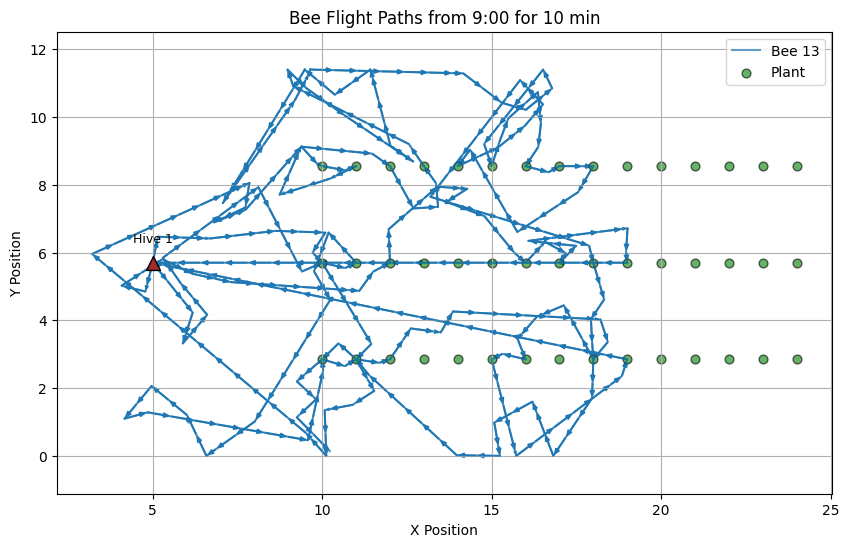

In [ ]:
%matplotlib inline
# Select bee IDs to visualize
vis_bees_path(df, bee_ids=[13], start_time_str="9:00", duration_minutes=10)

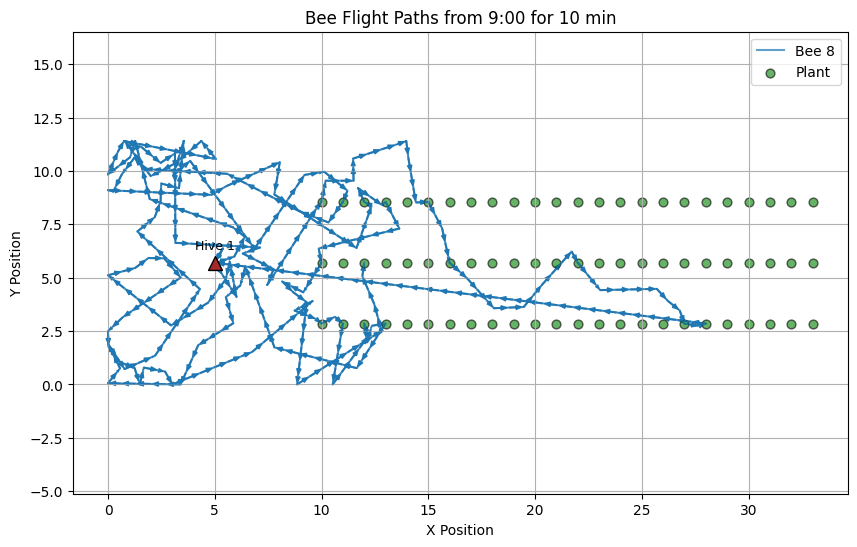

In [ ]:
%matplotlib inline
# Select bee IDs to visualize
vis_bees_path(df, bee_ids=[8], start_time_str="9:00", duration_minutes=10)

# Visualisation of specific sections of simulation

In [ ]:
import pickle
import pandas as pd

def load_run_dataframe(pkl_filename, run_id=0):
    """
    Loads a batch results pickle file and extracts the DataFrame for the given RunId.
    
    Parameters:
        pkl_filename (str): Path to the .pkl file.
        run_id (int): RunId to extract. Default = 0.
    
    Returns:
        df_run (pd.DataFrame): DataFrame with MultiIndex (Step, unique_id), filtered to the specified RunId.
    """

    # Load pkl
    with open(pkl_filename, "rb") as f:
        batch_results = pickle.load(f)

    # Convert to DataFrame
    df_all = pd.DataFrame(batch_results)

    # Extract RunID == run_id
    df_run = df_all[df_all["RunId"] == run_id].copy()

    # Set MultiIndex to match expected format
    df_run.set_index(["Step", "unique_id"], inplace=True)

    # Optional diagnostics
    print(f"Loaded RunID {run_id} from '{pkl_filename}' with {len(df_run)} rows")
    print(f"Steps range: {df_run.index.get_level_values('Step').min()} to {df_run.index.get_level_values('Step').max()}")
    print(f"Agent types: {df_run['Agent Type'].unique()}")

    return df_run


In [ ]:
%matplotlib notebook

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
from tqdm import tqdm
import matplotlib as mpl

def visualize_simulation(df, start_time_str="9:00", duration_minutes=10, dynamic_plants=True, frame_skip=1, highlight_bee_ids=None):
    """
    Visualizes bee movement, plants, and beehives within a time interval.
    df: DataFrame of the extracted run, indexed by (Step, unique_id)
    start_time_str: string, e.g. "9:00" (24h format)
    duration_minutes: number of minutes to visualize
    dynamic_plants: whether to update plant positions dynamically
    frame_skip: skip every Nth frame (default=1)
    highlight_bee_ids: list of bee IDs to highlight in red and label
    """

    mpl.rcParams['animation.embed_limit'] = 50

    bee_df = df[df["Agent Type"] == "bee"]
    plant_df = df[df["Agent Type"] == "plant"]
    beehive_df = df[df["Agent Type"] == "beehive"]

    steps = sorted(bee_df.index.get_level_values("Step").unique())

    def time_str_to_seconds(time_str):
        hh, mm = map(int, time_str.split(":"))
        return (hh - 9) * 3600 + mm * 60

    def step_to_time_str(step):
        hh = 9 + step // 3600
        mm = (step % 3600) // 60
        ss = step % 60
        return f"{hh:02d}:{mm:02d}:{ss:02d}"

    start_second = time_str_to_seconds(start_time_str)
    end_second = start_second + duration_minutes * 60
    selected_steps = [step for step in steps if start_second <= step < end_second]

    if len(selected_steps) == 0:
        print("Warning: No steps found in the specified time interval.")
        return None, None

    print(f"Visualizing interval:")
    print(f"  Start time = {step_to_time_str(selected_steps[0])} (Step {selected_steps[0]})")
    print(f"  End time   = {step_to_time_str(selected_steps[-1])} (Step {selected_steps[-1]})")
    print(f"  Total frames to animate (with frame_skip={frame_skip}): {len(selected_steps[::frame_skip])}")

    plant_style_df = plant_df.loc[0].reset_index().set_index("unique_id")
    bee_style_df = bee_df.loc[0].reset_index().set_index("unique_id")
    beehive_df_static = beehive_df.loc[0].reset_index()

    fig, ax = plt.subplots(figsize=(120/2, 2.85 * 2))
    ax.set_facecolor("gray")

    x_min, x_max = 0, 120
    y_min, y_max = 0, 2.85 * 4
    for x0, y0, x1, y1 in [(x_min, y_min, x_max, y_min), (x_min, y_max, x_max, y_max),
                          (x_min, y_min, x_min, y_max), (x_max, y_min, x_max, y_max)]:
        ax.plot([x0, x1], [y0, y1], color="black", linewidth=1.5)

    all_positions = bee_df["Bee Positions"].tolist() + plant_df["Bee Positions"].tolist() + beehive_df["Bee Positions"].tolist()
    all_x = [p[0] for p in all_positions]
    all_y = [p[1] for p in all_positions]
    ax.set_xlim(min(all_x) - 1, max(all_x) + 1)
    ax.set_ylim(min(all_y) - 1, max(all_y) + 1)
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")
    ax.set_title("Bee Movement Relative to Plants and Beehives")

    for _, hive in beehive_df_static.iterrows():
        pos = hive["Bee Positions"]
        style = hive["Plot Code"]
        ax.scatter(pos[0], pos[1],
                   marker=style.get("marker", "^"),
                   c=style.get("color", "brown"),
                   edgecolors=style.get("edgecolors", "none"),
                   linewidths=style.get("linewidths", 0.8),
                   s=80, zorder=0)
        ax.text(pos[0], pos[1] + 0.5, f"Hive {hive['unique_id']}",
                fontsize=8, ha='center', va='bottom', color='white', zorder=5)

    bee_scatters = {}
    plant_scatters = {}
    bee_texts = {}

    for uid, row in plant_style_df.iterrows():
        style = row["Plot Code"]
        scat = ax.scatter([], [],
                          marker=style.get("marker", "o"),
                          c=style.get("color"),
                          edgecolors=style.get("edgecolors", "black"),
                          linewidths=style.get("linewidths", 0.8),
                          s=40, zorder=1)
        plant_scatters[uid] = scat

    for uid, row in bee_style_df.iterrows():
        style = row["Plot Code"]
        color = "red" if highlight_bee_ids and uid in highlight_bee_ids else style.get("color")

        scat = ax.scatter([], [],
                          marker=style.get("marker", "o"),
                          c=color,
                          edgecolors=style.get("edgecolors", "black"),
                          linewidths=style.get("linewidths", 0.8),
                          s=40, zorder=2)
        bee_scatters[uid] = scat

        if highlight_bee_ids and uid in highlight_bee_ids:
            text = ax.text(0, 0, str(uid), fontsize=8, color="red", ha='center', va='bottom', zorder=3)
            bee_texts[uid] = text

    def update(frame):
        current_bees = bee_df.loc[frame]
        if isinstance(current_bees, pd.Series):
            current_bees = pd.DataFrame([current_bees])
        current_bees = current_bees.reset_index()
        for _, bee in current_bees.iterrows():
            uid = bee["unique_id"]
            pos = bee["Bee Positions"]
            if uid in bee_scatters:
                bee_scatters[uid].set_offsets([pos])
            if uid in bee_texts:
                bee_texts[uid].set_position((pos[0], pos[1] + 0.5))

        if dynamic_plants and frame in plant_df.index.get_level_values("Step"):
            current_plants = plant_df.loc[frame]
            if isinstance(current_plants, pd.Series):
                current_plants = pd.DataFrame([current_plants])
            current_plants = current_plants.reset_index()
            for _, plant in current_plants.iterrows():
                uid = plant["unique_id"]
                if uid in plant_scatters:
                    plant_scatters[uid].set_offsets([plant["Bee Positions"]])

        ax.set_title(f"Step {frame} ({step_to_time_str(frame)}) - Bee Movement Relative to Plants and Beehives")
        return list(bee_scatters.values()) + list(plant_scatters.values()) + list(bee_texts.values())

    frame_gen = (i for i in tqdm(selected_steps[::frame_skip], desc="Rendering animation"))
    anim = FuncAnimation(fig, update, frames=frame_gen, blit=False, interval=300, repeat=False)

    return anim, HTML(anim.to_jshtml())


In [ ]:
%matplotlib notebook

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
from tqdm import tqdm
import matplotlib as mpl

def visualize_simulation_partial(df, start_time_str="9:00", duration_minutes=10, dynamic_plants=True, frame_skip=1, highlight_bee_ids=None):
    """
    Visualize simulation, only rendering bees/plants within x <= 50.
    Displays highlighted bee ID, coordinates, forage_timer, and for each plant, nectar and scent mark timer below it.
    """

    mpl.rcParams['animation.embed_limit'] = 50

    bee_df = df[df["Agent Type"] == "bee"]
    plant_df = df[df["Agent Type"] == "plant"]
    beehive_df = df[df["Agent Type"] == "beehive"]

    steps = sorted(bee_df.index.get_level_values("Step").unique())

    def time_str_to_seconds(time_str):
        hh, mm = map(int, time_str.split(":"))
        return (hh - 9) * 3600 + mm * 60

    def step_to_time_str(step):
        hh = 9 + step // 3600
        mm = (step % 3600) // 60
        ss = step % 60
        return f"{hh:02d}:{mm:02d}:{ss:02d}"

    start_second = time_str_to_seconds(start_time_str)
    end_second = start_second + duration_minutes * 60
    selected_steps = [step for step in steps if start_second <= step < end_second]

    if len(selected_steps) == 0:
        print("Warning: No steps found in the specified time interval.")
        return None, None

    print(f"Visualizing interval:")
    print(f"  Start time = {step_to_time_str(selected_steps[0])} (Step {selected_steps[0]})")
    print(f"  End time   = {step_to_time_str(selected_steps[-1])} (Step {selected_steps[-1]})")
    print(f"  Total frames to animate (with frame_skip={frame_skip}): {len(selected_steps[::frame_skip])}")

    # --- Only render up to x = 50 ---
    x_min, x_max = 0, 50
    y_min, y_max = 0, 2.85 * 4

    fig, ax = plt.subplots(figsize=(x_max/2, (y_max-y_min)/2))
    ax.set_facecolor("gray")

    # Draw the border box with new x_max
    for x0, y0, x1, y1 in [
        (x_min, y_min, x_max, y_min),
        (x_min, y_max, x_max, y_max),
        (x_min, y_min, x_min, y_max),
        (x_max, y_min, x_max, y_max),
    ]:
        ax.plot([x0, x1], [y0, y1], color="black", linewidth=1.5)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")
    ax.set_title("Bee Movement Relative to Plants and Beehives (X ≤ 50)")

    # For style, use only the first frame's styles
    plant_style_df = plant_df.loc[0].reset_index().set_index("unique_id")
    bee_style_df = bee_df.loc[0].reset_index().set_index("unique_id")
    beehive_df_static = beehive_df.loc[0].reset_index()

    # Draw beehives (all hives, even if offscreen)
    for _, hive in beehive_df_static.iterrows():
        pos = hive["Bee Positions"]
        style = hive["Plot Code"]
        if pos[0] <= x_max:
            ax.scatter(pos[0], pos[1],
                       marker=style.get("marker", "^"),
                       c=style.get("color", "brown"),
                       edgecolors=style.get("edgecolors", "none"),
                       linewidths=style.get("linewidths", 0.8),
                       s=80, zorder=0)
            ax.text(pos[0], pos[1] + 0.5, f"Hive {hive['unique_id']}",
                    fontsize=8, ha='center', va='bottom', color='white', zorder=5)

    bee_scatters = {}
    plant_scatters = {}
    bee_texts = {}
    bee_coord_texts = {}
    bee_timer_texts = {}

    plant_nectar_texts = {}    # nectar (first line below)
    plant_scent_texts = {}     # scent mark timer (second line below)

    # Draw plants (only those in x <= 50)
    for uid, row in plant_style_df.iterrows():
        pos = row["Bee Positions"]
        if pos[0] <= x_max:
            style = row["Plot Code"]
            scat = ax.scatter([], [],
                              marker=style.get("marker", "o"),
                              c=style.get("color"),
                              edgecolors=style.get("edgecolors", "black"),
                              linewidths=style.get("linewidths", 0.8),
                              s=40, zorder=1)
            plant_scatters[uid] = scat
            # Add two texts: nectar and scent timer, both initially offscreen/empty
            nectar_text = ax.text(pos[0], pos[1] - 0.5, "", fontsize=8, color="blue", ha='center', va='top', zorder=2)
            scent_text = ax.text(pos[0], pos[1] - 0.8, "", fontsize=8, color="purple", ha='center', va='top', zorder=2)
            plant_nectar_texts[uid] = nectar_text
            plant_scent_texts[uid] = scent_text

    # Draw bees (all tracked for animation; will set positions only if x <= 50)
    for uid, row in bee_style_df.iterrows():
        style = row["Plot Code"]
        color = "red" if highlight_bee_ids and uid in highlight_bee_ids else style.get("color")

        scat = ax.scatter([], [],
                          marker=style.get("marker", "o"),
                          c=color,
                          edgecolors=style.get("edgecolors", "black"),
                          linewidths=style.get("linewidths", 0.8),
                          s=40, zorder=2)
        bee_scatters[uid] = scat

        if highlight_bee_ids and uid in highlight_bee_ids:
            # Three lines: ID, coords, forage_timer
            text_id = ax.text(0, 0, str(uid), fontsize=8, color="red", ha='center', va='bottom', zorder=3)
            text_coord = ax.text(0, 0, "", fontsize=8, color="red", ha='center', va='top', zorder=3)
            text_timer = ax.text(0, 0, "", fontsize=8, color="red", ha='center', va='top', zorder=3)
            bee_texts[uid] = text_id
            bee_coord_texts[uid] = text_coord
            bee_timer_texts[uid] = text_timer

    def update(frame):
        # Animate bees: show only those with x <= 50
        current_bees = bee_df.loc[frame]
        if isinstance(current_bees, pd.Series):
            current_bees = pd.DataFrame([current_bees])
        current_bees = current_bees.reset_index()
        for _, bee in current_bees.iterrows():
            uid = bee["unique_id"]
            pos = bee["Bee Positions"]
            x, y = pos[0], pos[1]
            forage_timer = bee.get("forage_timer", None)
            if uid in bee_scatters:
                if x <= x_max:
                    bee_scatters[uid].set_offsets([pos])
                else:
                    bee_scatters[uid].set_offsets([[np.nan, np.nan]])
            if uid in bee_texts:
                if x <= x_max:
                    bee_texts[uid].set_position((x, y + 1.0))
                    bee_coord_texts[uid].set_position((x, y + 0.65))
                    bee_coord_texts[uid].set_text(f"({x:.1f}, {y:.1f})")
                    bee_timer_texts[uid].set_position((x, y + 0.35))
                    if forage_timer is not None:
                        bee_timer_texts[uid].set_text(f"forage_timer={forage_timer}")
                    else:
                        bee_timer_texts[uid].set_text("")
                else:
                    bee_texts[uid].set_position((np.nan, np.nan))
                    bee_coord_texts[uid].set_position((np.nan, np.nan))
                    bee_timer_texts[uid].set_position((np.nan, np.nan))
                    bee_coord_texts[uid].set_text("")
                    bee_timer_texts[uid].set_text("")

        # Animate plants if dynamic and x <= 50
        if dynamic_plants and frame in plant_df.index.get_level_values("Step"):
            current_plants = plant_df.loc[frame]
            if isinstance(current_plants, pd.Series):
                current_plants = pd.DataFrame([current_plants])
            current_plants = current_plants.reset_index()
            for _, plant in current_plants.iterrows():
                uid = plant["unique_id"]
                pos = plant["Bee Positions"]
                x, y = pos[0], pos[1]
                nectar = plant.get("nectar", None)
                scent = plant.get("scent_mark_timer", None)
                if uid in plant_scatters:
                    if x <= x_max:
                        plant_scatters[uid].set_offsets([pos])
                        # Update nectar and scent mark timer text below plant
                        plant_nectar_texts[uid].set_position((x, y - 0.5))
                        if nectar is not None:
                            plant_nectar_texts[uid].set_text(f"nectar={nectar:.1f}")
                        else:
                            plant_nectar_texts[uid].set_text("")
                        plant_scent_texts[uid].set_position((x, y - 0.8))
                        if scent is not None:
                            plant_scent_texts[uid].set_text(f"scent={scent}")
                        else:
                            plant_scent_texts[uid].set_text("")
                    else:
                        plant_scatters[uid].set_offsets([[np.nan, np.nan]])
                        plant_nectar_texts[uid].set_position((np.nan, np.nan))
                        plant_nectar_texts[uid].set_text("")
                        plant_scent_texts[uid].set_position((np.nan, np.nan))
                        plant_scent_texts[uid].set_text("")

        ax.set_title(f"Step {frame} ({step_to_time_str(frame)}) - Bee Movement Relative to Plants and Beehives (X ≤ 50)")
        return (list(bee_scatters.values())
                + list(plant_scatters.values())
                + list(bee_texts.values())
                + list(bee_coord_texts.values())
                + list(bee_timer_texts.values())
                + list(plant_nectar_texts.values())
                + list(plant_scent_texts.values()))

    frame_gen = (i for i in tqdm(selected_steps[::frame_skip], desc="Rendering animation"))
    anim = FuncAnimation(fig, update, frames=frame_gen, blit=False, interval=300, repeat=False)

    return anim, HTML(anim.to_jshtml())


In [ ]:
### NEW CODE
%matplotlib notebook

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
from tqdm import tqdm
import matplotlib as mpl

def visualize_simulation_partial(df, start_time_str="9:00", duration_minutes=10, dynamic_plants=True, frame_skip=1, highlight_bee_ids=None):
    """
    Visualize simulation, only rendering bees/plants within x <= 50.
    Displays highlighted bee ID, coordinates, forage_timer, and for each plant, nectar and scent mark timer below it.
    """

    mpl.rcParams['animation.embed_limit'] = 50

    bee_df = df[df["Agent Type"] == "bee"]
    plant_df = df[df["Agent Type"] == "plant"]
    beehive_df = df[df["Agent Type"] == "beehive"]

    steps = sorted(bee_df.index.get_level_values("Step").unique())

    def time_str_to_seconds(time_str):
        hh, mm = map(int, time_str.split(":"))
        return (hh - 9) * 3600 + mm * 60

    def step_to_time_str(step):
        hh = 9 + step // 3600
        mm = (step % 3600) // 60
        ss = step % 60
        return f"{hh:02d}:{mm:02d}:{ss:02d}"

    start_second = time_str_to_seconds(start_time_str)
    end_second = start_second + duration_minutes * 60
    selected_steps = [step for step in steps if start_second <= step < end_second]

    if len(selected_steps) == 0:
        print("Warning: No steps found in the specified time interval.")
        return None, None

    print(f"Visualizing interval:")
    print(f"  Start time = {step_to_time_str(selected_steps[0])} (Step {selected_steps[0]})")
    print(f"  End time   = {step_to_time_str(selected_steps[-1])} (Step {selected_steps[-1]})")
    print(f"  Total frames to animate (with frame_skip={frame_skip}): {len(selected_steps[::frame_skip])}")

    # --- Only render up to x = 50 ---
    x_min, x_max = 0, 50
    y_min, y_max = 0, 2.85 * 4

    fig, ax = plt.subplots(figsize=(x_max/2, (y_max-y_min)/2))
    ax.set_facecolor("gray")

    # Draw the border box with new x_max
    for x0, y0, x1, y1 in [
        (x_min, y_min, x_max, y_min),
        (x_min, y_max, x_max, y_max),
        (x_min, y_min, x_min, y_max),
        (x_max, y_min, x_max, y_max),
    ]:
        ax.plot([x0, x1], [y0, y1], color="black", linewidth=1.5)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")
    ax.set_title("Bee Movement Relative to Plants and Beehives (X ≤ 50)")

    # For style, use only the first frame's styles
    plant_style_df = plant_df.loc[0].reset_index().set_index("unique_id")
    bee_style_df = bee_df.loc[0].reset_index().set_index("unique_id")
    beehive_df_static = beehive_df.loc[0].reset_index()

    # Draw beehives (all hives, even if offscreen)
    for _, hive in beehive_df_static.iterrows():
        pos = hive["Bee Positions"]
        style = hive["Plot Code"]
        if pos[0] <= x_max:
            ax.scatter(pos[0], pos[1],
                       marker=style.get("marker", "^"),
                       c=style.get("color", "brown"),
                       edgecolors=style.get("edgecolors", "none"),
                       linewidths=style.get("linewidths", 0.8),
                       s=80, zorder=0)
            ax.text(pos[0], pos[1] + 0.5, f"Hive {hive['unique_id']}",
                    fontsize=8, ha='center', va='bottom', color='white', zorder=5)

    bee_scatters = {}
    plant_scatters = {}
    bee_texts = {}
    bee_coord_texts = {}
    bee_timer_texts = {}

    plant_nectar_texts = {}    # nectar (first line below)
    plant_scent_texts = {}     # scent mark timer (second line below)

    # Draw plants (only those in x <= 50)
    for uid, row in plant_style_df.iterrows():
        pos = row["Bee Positions"]
        if pos[0] <= x_max:
            style = row["Plot Code"]
            scat = ax.scatter([], [],
                              marker=style.get("marker", "o"),
                              c=style.get("color"),
                              edgecolors=style.get("edgecolors", "black"),
                              linewidths=style.get("linewidths", 0.8),
                              s=40, zorder=1)
            plant_scatters[uid] = scat
            # Add two texts: nectar and scent timer, both initially offscreen/empty
            nectar_text = ax.text(pos[0], pos[1] - 0.5, "", fontsize=8, color="blue", ha='center', va='top', zorder=2)
            scent_text = ax.text(pos[0], pos[1] - 0.8, "", fontsize=8, color="purple", ha='center', va='top', zorder=2)
            plant_nectar_texts[uid] = nectar_text
            plant_scent_texts[uid] = scent_text

    # Draw bees (all tracked for animation; will set positions only if x <= 50)
    for uid, row in bee_style_df.iterrows():
        style = row["Plot Code"]
        color = "red" if highlight_bee_ids and uid in highlight_bee_ids else style.get("color")

        scat = ax.scatter([], [],
                          marker=style.get("marker", "o"),
                          c=color,
                          edgecolors=style.get("edgecolors", "black"),
                          linewidths=style.get("linewidths", 0.8),
                          s=40, zorder=2)
        bee_scatters[uid] = scat

        if highlight_bee_ids and uid in highlight_bee_ids:
            # Three lines: ID, coords, forage_timer
            text_id = ax.text(0, 0, str(uid), fontsize=8, color="red", ha='center', va='bottom', zorder=3)
            text_coord = ax.text(0, 0, "", fontsize=8, color="red", ha='center', va='top', zorder=3)
            text_timer = ax.text(0, 0, "", fontsize=8, color="red", ha='center', va='top', zorder=3)
            bee_texts[uid] = text_id
            bee_coord_texts[uid] = text_coord
            bee_timer_texts[uid] = text_timer

    def update(frame):
        # Animate bees: show only those with x <= 50
        current_bees = bee_df.loc[frame]
        if isinstance(current_bees, pd.Series):
            current_bees = pd.DataFrame([current_bees])
        current_bees = current_bees.reset_index()
        for _, bee in current_bees.iterrows():
            uid = bee["unique_id"]
            pos = bee["Bee Positions"]
            x, y = pos[0], pos[1]

            # Support for both "forage_timer" and "Forage Timer" columns:
            forage_timer = None
            if "forage_timer" in bee:
                forage_timer = bee["forage_timer"]
            elif "Forage Timer" in bee:
                forage_timer = bee["Forage Timer"]

            if uid in bee_scatters:
                if x <= x_max:
                    bee_scatters[uid].set_offsets([pos])
                else:
                    bee_scatters[uid].set_offsets([[np.nan, np.nan]])
            if uid in bee_texts:
                if x <= x_max:
                    bee_texts[uid].set_position((x, y + 1.0))
                    bee_coord_texts[uid].set_position((x, y + 0.65))
                    bee_coord_texts[uid].set_text(f"({x:.1f}, {y:.1f})")
                    bee_timer_texts[uid].set_position((x, y + 0.35))
                    if forage_timer is not None and not (isinstance(forage_timer, float) and np.isnan(forage_timer)):
                        bee_timer_texts[uid].set_text(f"forage_timer={forage_timer}")
                    else:
                        bee_timer_texts[uid].set_text("")
                else:
                    bee_texts[uid].set_position((np.nan, np.nan))
                    bee_coord_texts[uid].set_position((np.nan, np.nan))
                    bee_timer_texts[uid].set_position((np.nan, np.nan))
                    bee_coord_texts[uid].set_text("")
                    bee_timer_texts[uid].set_text("")

        # Animate plants if dynamic and x <= 50
        if dynamic_plants and frame in plant_df.index.get_level_values("Step"):
            current_plants = plant_df.loc[frame]
            if isinstance(current_plants, pd.Series):
                current_plants = pd.DataFrame([current_plants])
            current_plants = current_plants.reset_index()
            for _, plant in current_plants.iterrows():
                uid = plant["unique_id"]
                pos = plant["Bee Positions"]
                x, y = pos[0], pos[1]
                nectar = plant.get("Plant nectar amount", None)
                scent = plant.get("Plant scent timer", None)
                if uid in plant_scatters:
                    if x <= x_max:
                        plant_scatters[uid].set_offsets([pos])
                        # Update nectar and scent mark timer text below plant
                        plant_nectar_texts[uid].set_position((x, y - 0.5))
                        if nectar is not None and not (isinstance(nectar, float) and np.isnan(nectar)):
                            plant_nectar_texts[uid].set_text(f"nectar={nectar:.1f}")
                        else:
                            plant_nectar_texts[uid].set_text("")
                        plant_scent_texts[uid].set_position((x, y - 0.8))
                        if scent is not None and not (isinstance(scent, float) and np.isnan(scent)):
                            plant_scent_texts[uid].set_text(f"scent={scent}")
                        else:
                            plant_scent_texts[uid].set_text("")
                    else:
                        plant_scatters[uid].set_offsets([[np.nan, np.nan]])
                        plant_nectar_texts[uid].set_position((np.nan, np.nan))
                        plant_nectar_texts[uid].set_text("")
                        plant_scent_texts[uid].set_position((np.nan, np.nan))
                        plant_scent_texts[uid].set_text("")

        ax.set_title(f"Step {frame} ({step_to_time_str(frame)}) - Bee Movement Relative to Plants and Beehives (X ≤ 50)")
        return (list(bee_scatters.values())
                + list(plant_scatters.values())
                + list(bee_texts.values())
                + list(bee_coord_texts.values())
                + list(bee_timer_texts.values())
                + list(plant_nectar_texts.values())
                + list(plant_scent_texts.values()))

    frame_gen = (i for i in tqdm(selected_steps[::frame_skip], desc="Rendering animation"))
    anim = FuncAnimation(fig, update, frames=frame_gen, blit=False, interval=300, repeat=False)

    return anim, HTML(anim.to_jshtml())


In [ ]:
dataset_name = "sim_results_my_behavior_seed_0.pkl"
df_run0 = load_run_dataframe(dataset_name, run_id=0)

anim, html = visualize_simulation_partial(df_run0, start_time_str="9:00", duration_minutes=20, highlight_bee_ids=[3, 5, 14])
html

Loaded RunID 0 from 'sim_results_my_behavior_seed_0.pkl' with 255425 rows
Steps range: 0 to 600
Agent types: ['beehive' 'bee' 'plant']
Visualizing interval:
  Start time = 09:00:00 (Step 0)
  End time   = 09:10:00 (Step 600)
  Total frames to animate (with frame_skip=1): 601


<IPython.core.display.Javascript object>

Rendering animation:   0%|          | 0/601 [00:00<?, ?it/s]C:\Users\ssha0310\AppData\Local\Temp\ipykernel_21580\1383524640.py:221: UserWarning: frames=<generator object visualize_simulation_partial.<locals>.<genexpr> at 0x00000255AF29EA40> which we can infer the length of, did not pass an explicit *save_count* and passed cache_frame_data=True.  To avoid a possibly unbounded cache, frame data caching has been disabled. To suppress this warning either pass `cache_frame_data=False` or `save_count=MAX_FRAMES`.
  anim = FuncAnimation(fig, update, frames=frame_gen, blit=False, interval=300, repeat=False)
Rendering animation:   2%|▏         | 13/601 [00:01<01:31,  6.45it/s]

: 

In [ ]:
# Saving the animation to HTML file
with open("simulation_animation.html", "w") as f:
    f.write(anim.to_jshtml())

In [ ]:
# For visualization in a web browser
import webbrowser
webbrowser.open("simulation_animation.html")

True